In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/cleaned/adult_income_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (48813, 20)


In [4]:
df.duplicated().sum()

np.int64(0)

In [3]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source_split,high_income,age_group,hours_group,net_capital
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train,0,36-45,21-40,2174
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train,0,46-55,0-20,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train,0,36-45,21-40,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train,0,46-55,21-40,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train,0,26-35,21-40,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48813 entries, 0 to 48812
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48813 non-null  int64
 1   workclass       48813 non-null  str  
 2   fnlwgt          48813 non-null  int64
 3   education       48813 non-null  str  
 4   education_num   48813 non-null  int64
 5   marital_status  48813 non-null  str  
 6   occupation      48813 non-null  str  
 7   relationship    48813 non-null  str  
 8   race            48813 non-null  str  
 9   sex             48813 non-null  str  
 10  capital_gain    48813 non-null  int64
 11  capital_loss    48813 non-null  int64
 12  hours_per_week  48813 non-null  int64
 13  native_country  48813 non-null  str  
 14  income          48813 non-null  str  
 15  source_split    48813 non-null  str  
 16  high_income     48813 non-null  int64
 17  age_group       48813 non-null  str  
 18  hours_group     48813 non-null  str  

In [5]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,high_income,net_capital
count,48813.000000,4.881300e+04,48813.000000,48813.000000,48813.000000,48813.000000,48813.000000,48813.000000
mean,38.647348,1.896679e+05,10.078688,1079.708705,87.554299,40.425051,0.239383,992.154406
std,13.709005,1.056062e+05,2.570257,7454.185982,403.118605,12.390954,0.426711,7477.731168
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000,-4356.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000,0.000000,0.000000
50%,37.000000,1.781400e+05,10.000000,0.000000,0.000000,40.000000,0.000000,0.000000
75%,48.000000,2.376200e+05,12.000000,0.000000,0.000000,45.000000,0.000000,0.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000,99999.000000


In [6]:
df["income"].value_counts()

income
<=50K    37128
>50K     11685
Name: count, dtype: int64

In [7]:
income_percentage = df["income"].value_counts(normalize=True) * 100

print(income_percentage)

income
<=50K    76.061705
>50K     23.938295
Name: proportion, dtype: float64


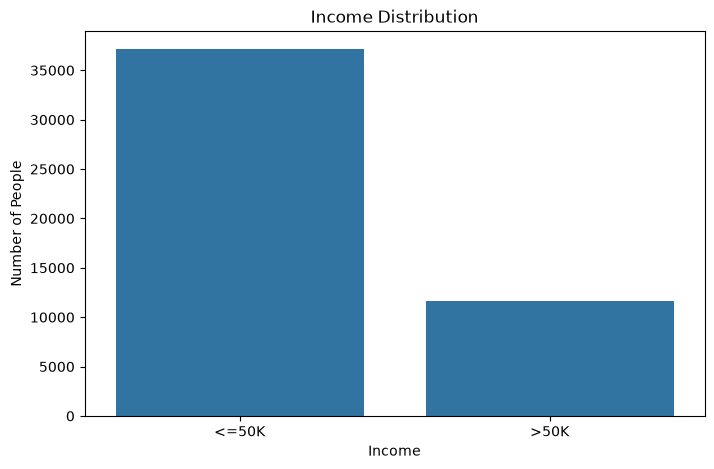

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="income")

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")

plt.show()

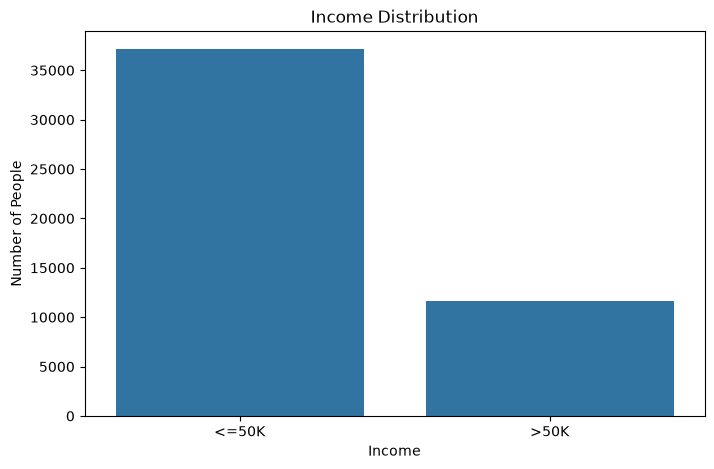

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="income")

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of People")

plt.savefig("../reports/charts/income_distribution.png",
            bbox_inches="tight")

plt.show()

In [10]:
education_income = pd.crosstab(
    df["education"],
    df["income"],
    normalize="index"
) * 100

print(education_income)

income            <=50K       >50K
education                         
10th          93.736501   6.263499
11th          94.922737   5.077263
12th          92.682927   7.317073
1st-4th       96.734694   3.265306
5th-6th       94.685039   5.314961
7th-8th       93.501048   6.498952
9th           94.576720   5.423280
Assoc-acdm    74.203623  25.796377
Assoc-voc     74.660194  25.339806
Bachelors     58.690773  41.309227
Doctorate     27.441077  72.558923
HS-grad       84.141472  15.858528
Masters       45.067771  54.932229
Preschool     98.780488   1.219512
Prof-school   26.019185  73.980815
Some-college  81.028613  18.971387


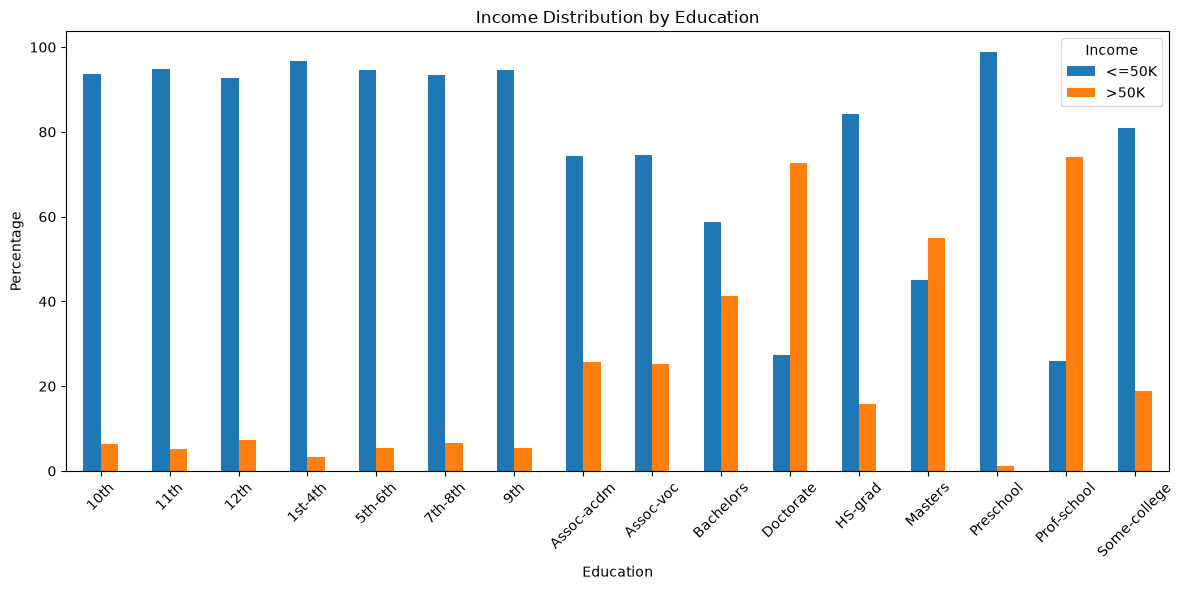

In [11]:
education_income.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Income Distribution by Education")
plt.xlabel("Education")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

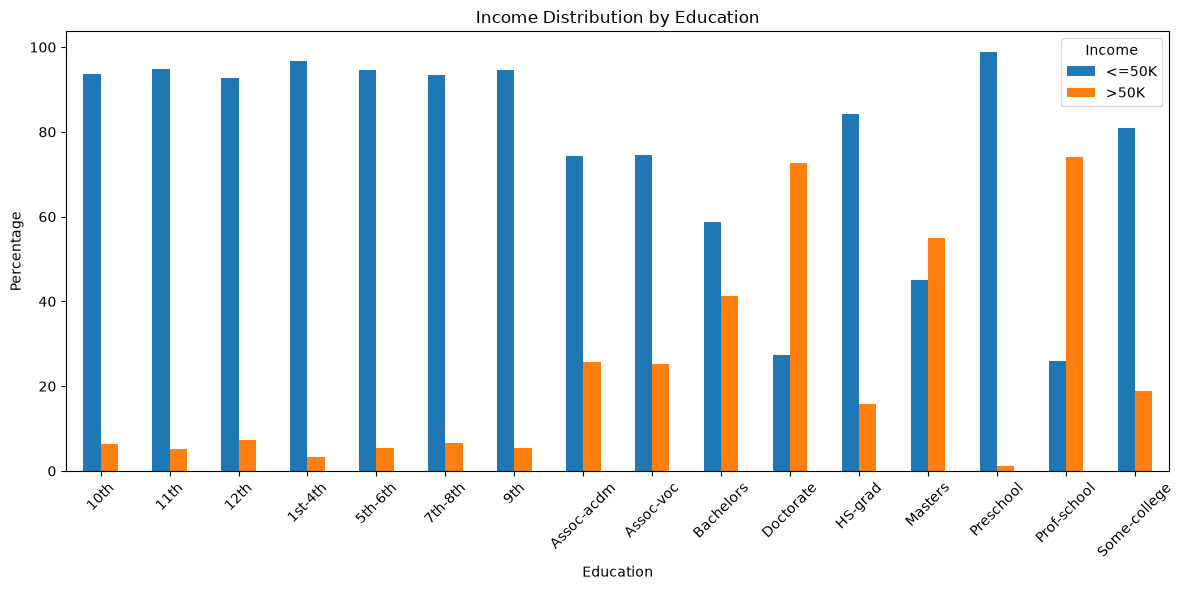

In [12]:
education_income.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Income Distribution by Education")
plt.xlabel("Education")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/education_income.png",
    bbox_inches="tight"
)

plt.show()

In [13]:
occupation_income = pd.crosstab(
    df["occupation"],
    df["income"],
    normalize="index"
) * 100

print(occupation_income)

income                 <=50K       >50K
occupation                             
Adm-clerical       86.305278  13.694722
Armed-Forces       66.666667  33.333333
Craft-repair       77.353856  22.646144
Exec-managerial    52.202498  47.797502
Farming-fishing    88.365837  11.634163
Handlers-cleaners  93.336552   6.663448
Machine-op-inspct  87.711163  12.288837
Other-service      95.852816   4.147184
Priv-house-serv    98.750000   1.250000
Prof-specialty     54.872710  45.127290
Protective-serv    68.667345  31.332655
Sales              73.201308  26.798692
Tech-support       70.934256  29.065744
Transport-moving   79.575372  20.424628
Unknown            90.566038   9.433962


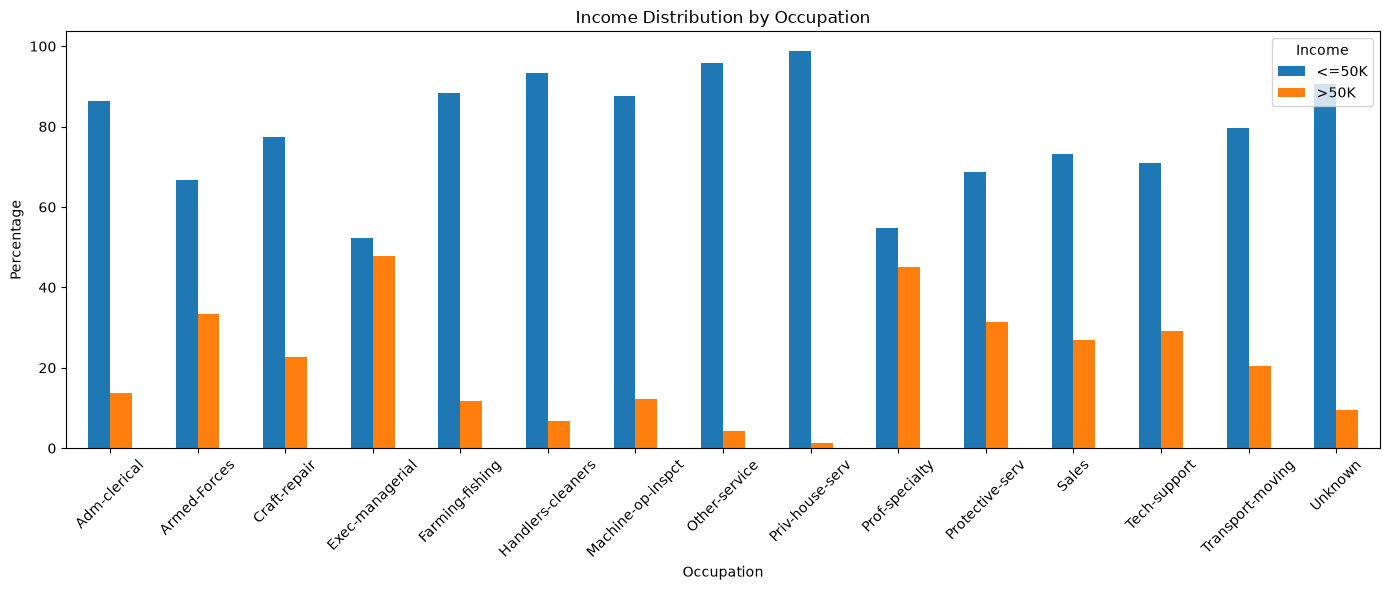

In [14]:
occupation_income.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Income Distribution by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

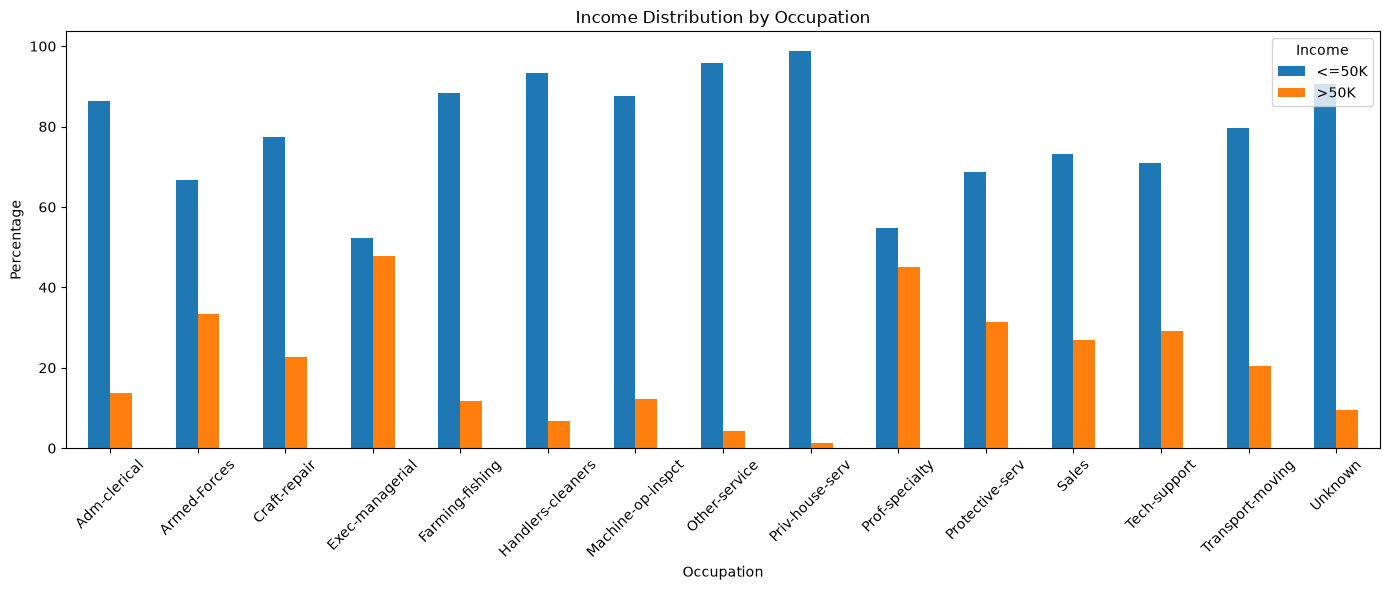

In [15]:
occupation_income.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Income Distribution by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/occupation_income.png",
    bbox_inches="tight"
)

plt.show()

In [16]:
print(df["age_group"].value_counts().sort_index())

age_group
18-25     9614
26-35    12713
36-45    11947
46-55     8292
56-65     4445
66+       1802
Name: count, dtype: int64


In [17]:
age_income = pd.crosstab(
    df["age_group"],
    df["income"],
    normalize="index"
) * 100

print(age_income)

income         <=50K       >50K
age_group                      
18-25      98.242147   1.757853
26-35      81.286872  18.713128
36-45      65.439022  34.560978
46-55      60.745297  39.254703
56-65      68.593926  31.406074
66+        80.188679  19.811321


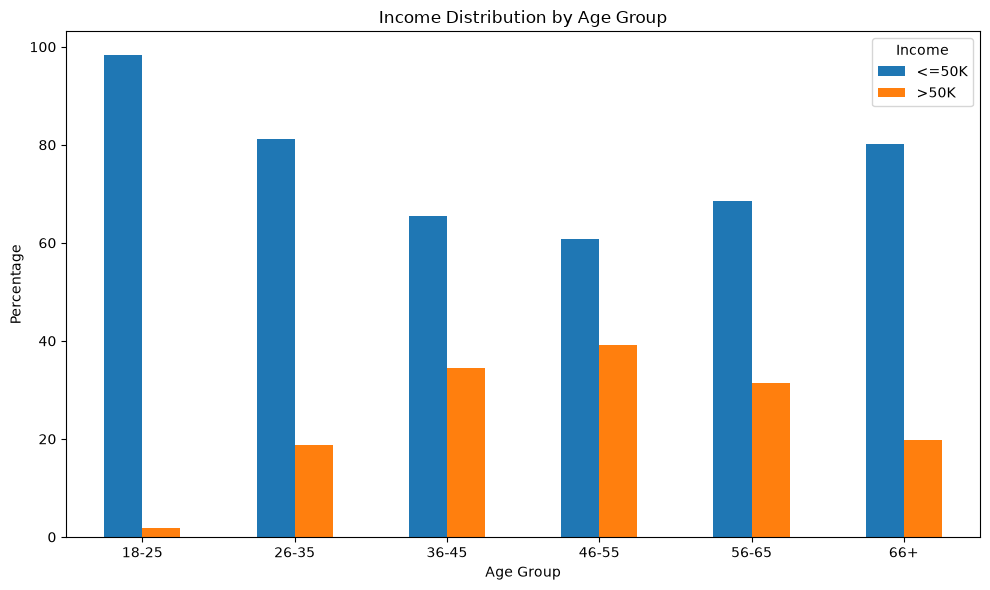

In [18]:
age_income.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Income Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

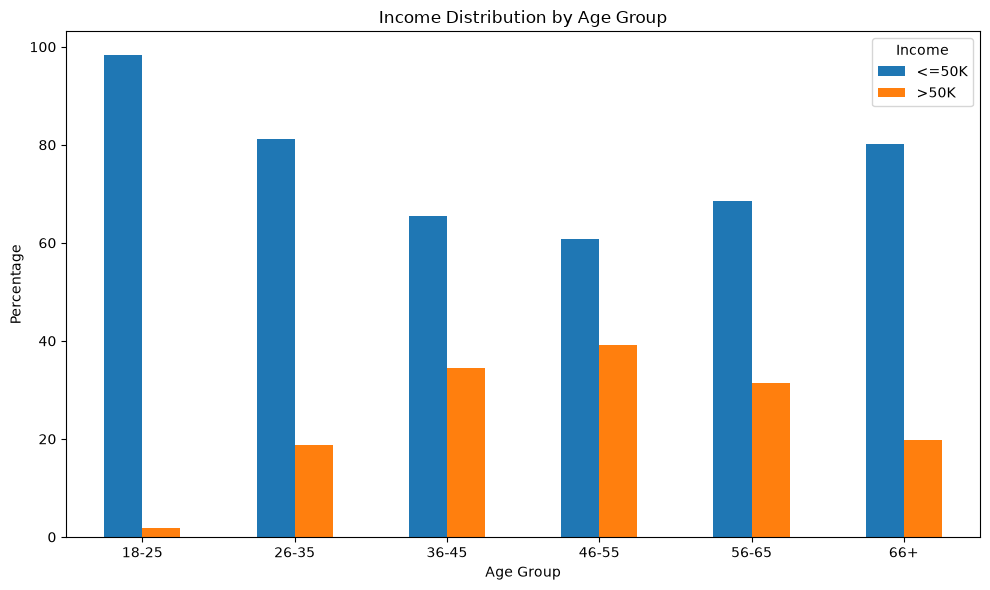

In [19]:
age_income.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Income Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/age_income.png",
    bbox_inches="tight"
)

plt.show()

In [20]:
workclass_income = pd.crosstab(
    df["workclass"],
    df["income"],
    normalize="index"
) * 100

print(workclass_income)

income                 <=50K       >50K
workclass                              
Federal-gov        60.824022  39.175978
Local-gov          70.440051  29.559949
Never-worked      100.000000   0.000000
Private            78.201836  21.798164
Self-emp-inc       44.628099  55.371901
Self-emp-not-inc   72.105672  27.894328
State-gov          73.245835  26.754165
Unknown            90.532333   9.467667
Without-pay        90.476190   9.523810


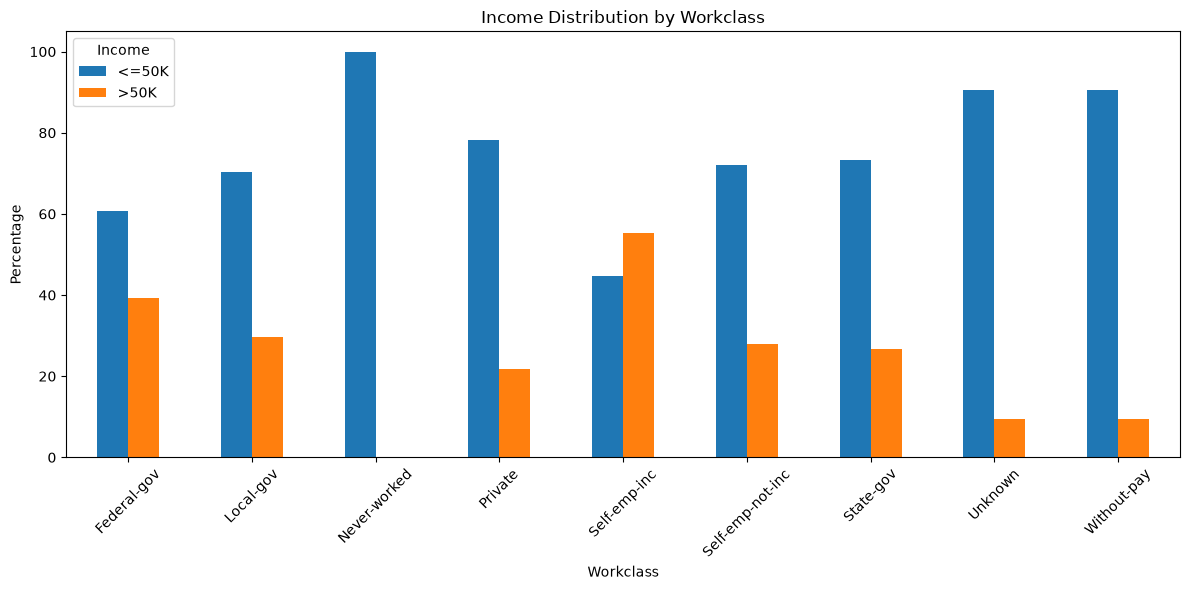

In [21]:
workclass_income.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Income Distribution by Workclass")
plt.xlabel("Workclass")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

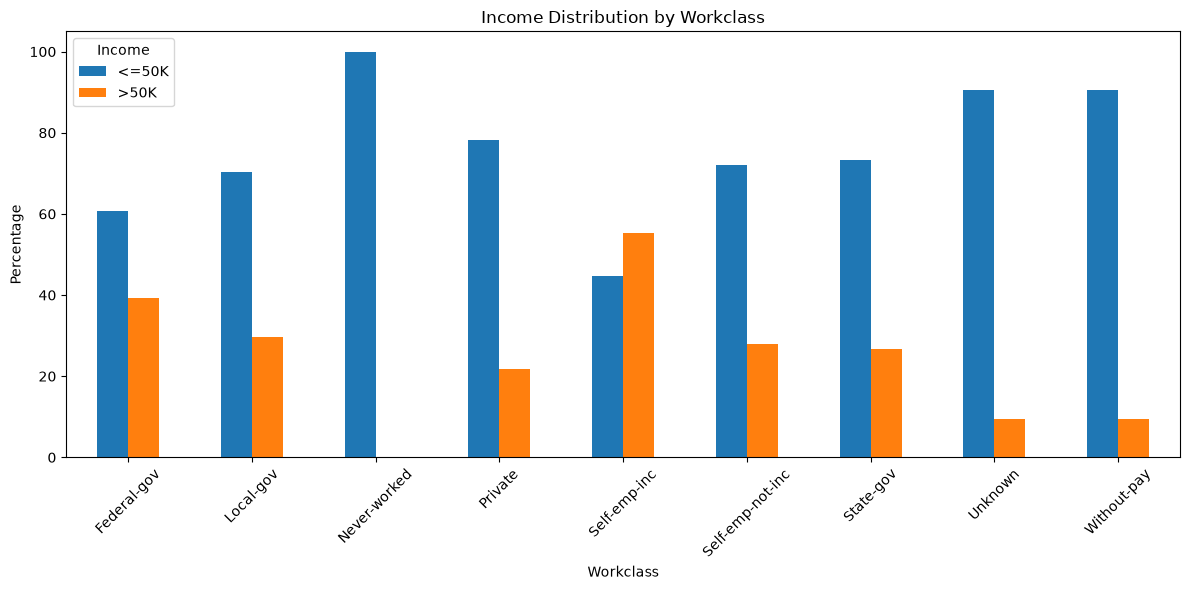

In [22]:
workclass_income.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Income Distribution by Workclass")
plt.xlabel("Workclass")
plt.ylabel("Percentage")

plt.xticks(rotation=45)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/workclass_income.png",
    bbox_inches="tight"
)

plt.show()

In [23]:
sex_income = pd.crosstab(
    df["sex"],
    df["income"],
    normalize="index"
) * 100

print(sex_income)

income      <=50K       >50K
sex                         
Female  89.068100  10.931900
Male    69.611719  30.388281


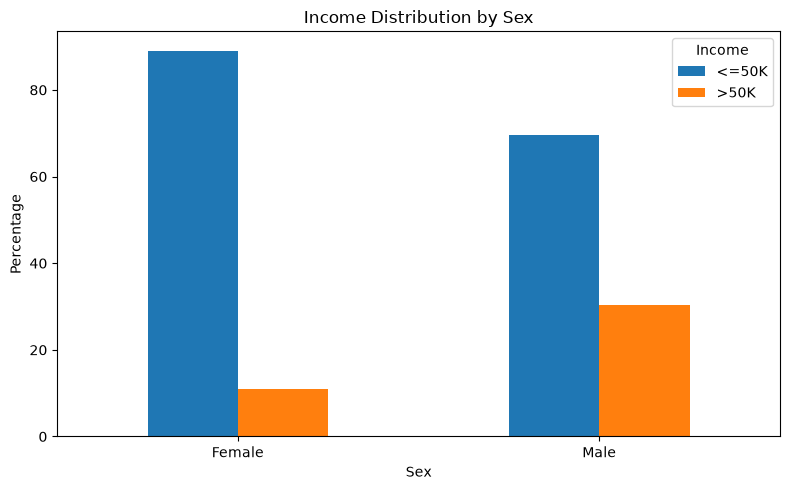

In [24]:
sex_income.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Income Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

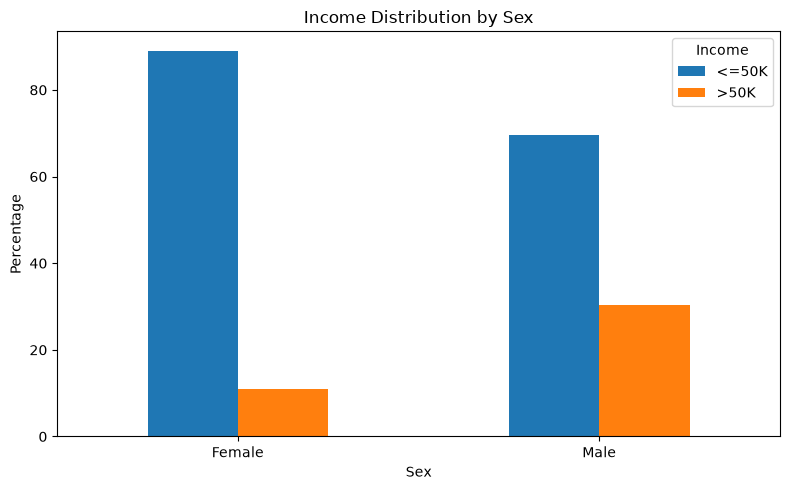

In [25]:
sex_income.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Income Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/sex_income.png",
    bbox_inches="tight"
)

plt.show()

In [26]:
print(
    df.groupby("income", observed=True)["hours_per_week"].describe()
)

          count       mean        std  min   25%   50%   75%   max
income                                                            
<=50K   37128.0  38.842599  12.356307  1.0  35.0  40.0  40.0  99.0
>50K    11685.0  45.453145  11.091986  1.0  40.0  40.0  50.0  99.0


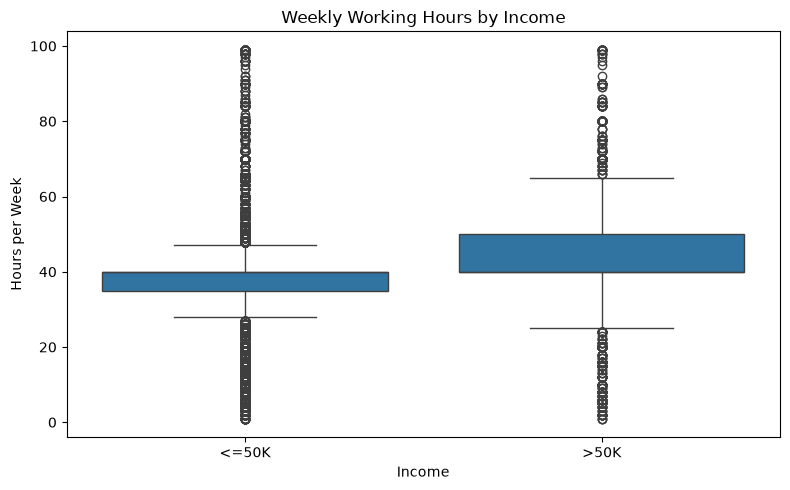

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours_per_week"
)

plt.title("Weekly Working Hours by Income")
plt.xlabel("Income")
plt.ylabel("Hours per Week")

plt.tight_layout()
plt.show()

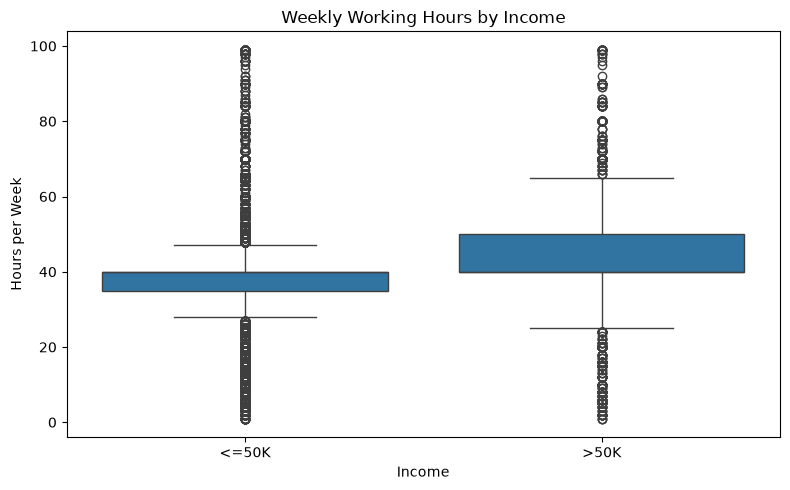

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours_per_week"
)

plt.title("Weekly Working Hours by Income")
plt.xlabel("Income")
plt.ylabel("Hours per Week")

plt.tight_layout()

plt.savefig(
    "../reports/charts/hours_income_boxplot.png",
    bbox_inches="tight"
)

plt.show()

In [29]:
hours_income = pd.crosstab(
    df["hours_group"],
    df["income"],
    normalize="index"
) * 100

print(hours_income)

income           <=50K       >50K
hours_group                      
0-20         93.232914   6.767086
21-40        81.201279  18.798721
41-60        59.419146  40.580854
61+          64.260143  35.739857


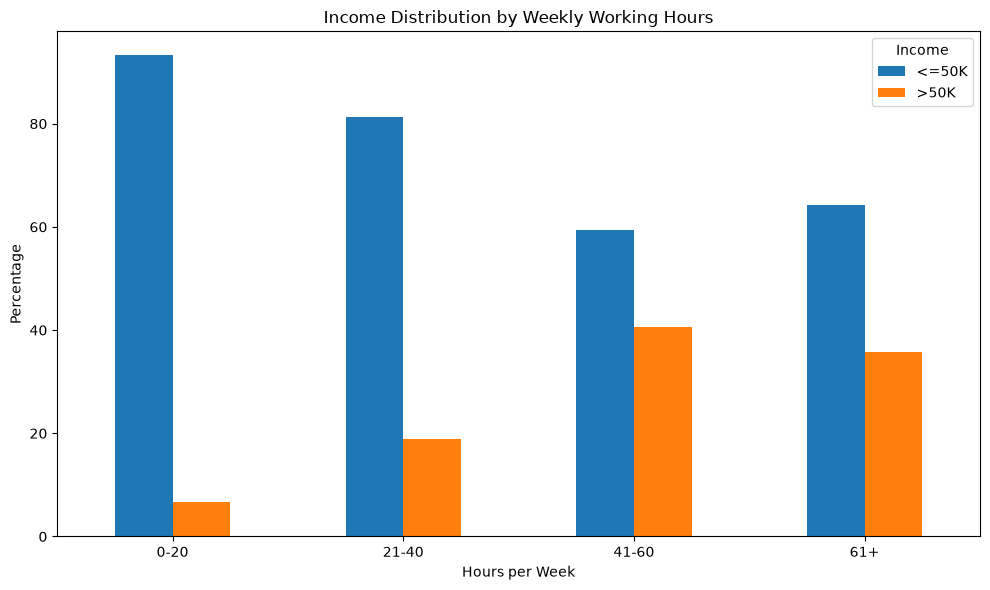

In [30]:
hours_income.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Income Distribution by Weekly Working Hours")
plt.xlabel("Hours per Week")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()
plt.show()

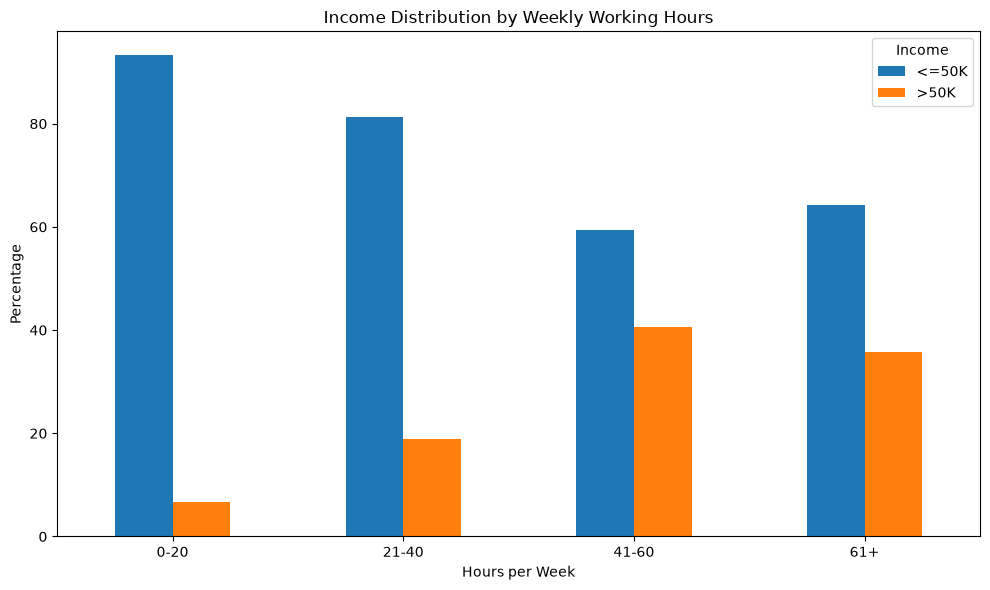

In [31]:
hours_income.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Income Distribution by Weekly Working Hours")
plt.xlabel("Hours per Week")
plt.ylabel("Percentage")

plt.xticks(rotation=0)
plt.legend(title="Income")

plt.tight_layout()

plt.savefig(
    "../reports/charts/hours_income.png",
    bbox_inches="tight"
)

plt.show()

In [32]:
print(
    df[
        ["capital_gain", "capital_loss", "net_capital"]
    ].describe()
)

       capital_gain  capital_loss   net_capital
count  48813.000000  48813.000000  48813.000000
mean    1079.708705     87.554299    992.154406
std     7454.185982    403.118605   7477.731168
min        0.000000      0.000000  -4356.000000
25%        0.000000      0.000000      0.000000
50%        0.000000      0.000000      0.000000
75%        0.000000      0.000000      0.000000
max    99999.000000   4356.000000  99999.000000


In [33]:
print(
    df.groupby("income", observed=True)["capital_gain"].describe()
)

          count         mean           std  min  25%  50%  75%      max
income                                                                 
<=50K   37128.0   147.117216    937.085843  0.0  0.0  0.0  0.0  41310.0
>50K    11685.0  4042.931365  14757.939193  0.0  0.0  0.0  0.0  99999.0


In [34]:
print(
    df.groupby("income", observed=True)["capital_loss"].describe()
)

          count        mean         std  min  25%  50%  75%     max
income                                                             
<=50K   37128.0   54.191311  313.430508  0.0  0.0  0.0  0.0  4356.0
>50K    11685.0  193.562088  593.256977  0.0  0.0  0.0  0.0  3683.0


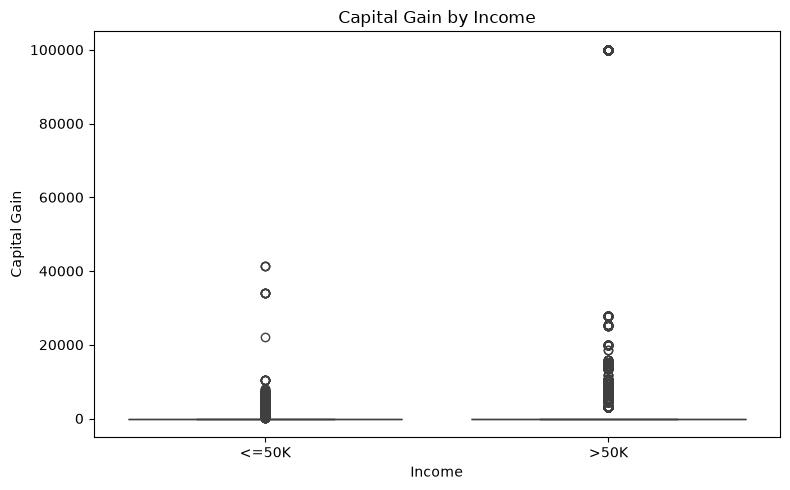

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="income",
    y="capital_gain"
)

plt.title("Capital Gain by Income")
plt.xlabel("Income")
plt.ylabel("Capital Gain")

plt.tight_layout()
plt.show()

In [36]:
numeric_columns = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "high_income",
    "net_capital"
]

correlation = df[numeric_columns].corr()

print(correlation)

                     age    fnlwgt  education_num  capital_gain  capital_loss  \
age             1.000000 -0.076474       0.030760      0.077221      0.056908   
fnlwgt         -0.076474  1.000000      -0.038798     -0.003713     -0.004375   
education_num   0.030760 -0.038798       1.000000      0.125186      0.080969   
capital_gain    0.077221 -0.003713       0.125186      1.000000     -0.031460   
capital_loss    0.056908 -0.004375       0.080969     -0.031460      1.000000   
hours_per_week  0.071322 -0.013516       0.143872      0.082154      0.054440   
high_income     0.230335 -0.006376       0.332746      0.223014      0.147527   
net_capital     0.073910 -0.003465       0.120426      0.998547     -0.085270   

                hours_per_week  high_income  net_capital  
age                   0.071322     0.230335     0.073910  
fnlwgt               -0.013516    -0.006376    -0.003465  
education_num         0.143872     0.332746     0.120426  
capital_gain          0.082154    

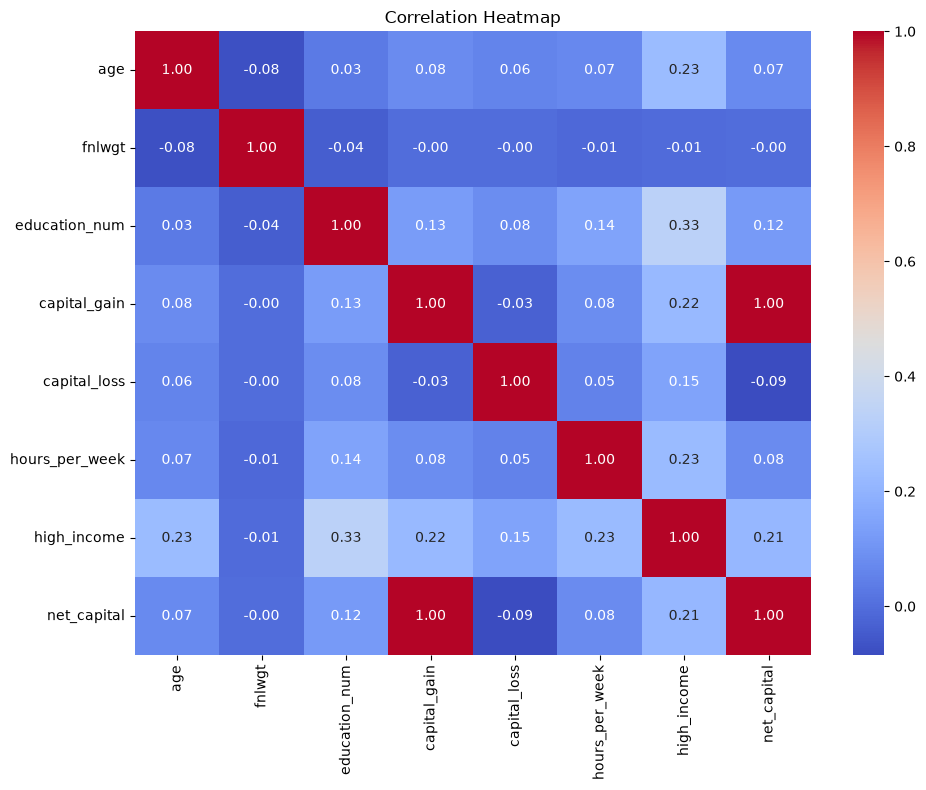

In [37]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

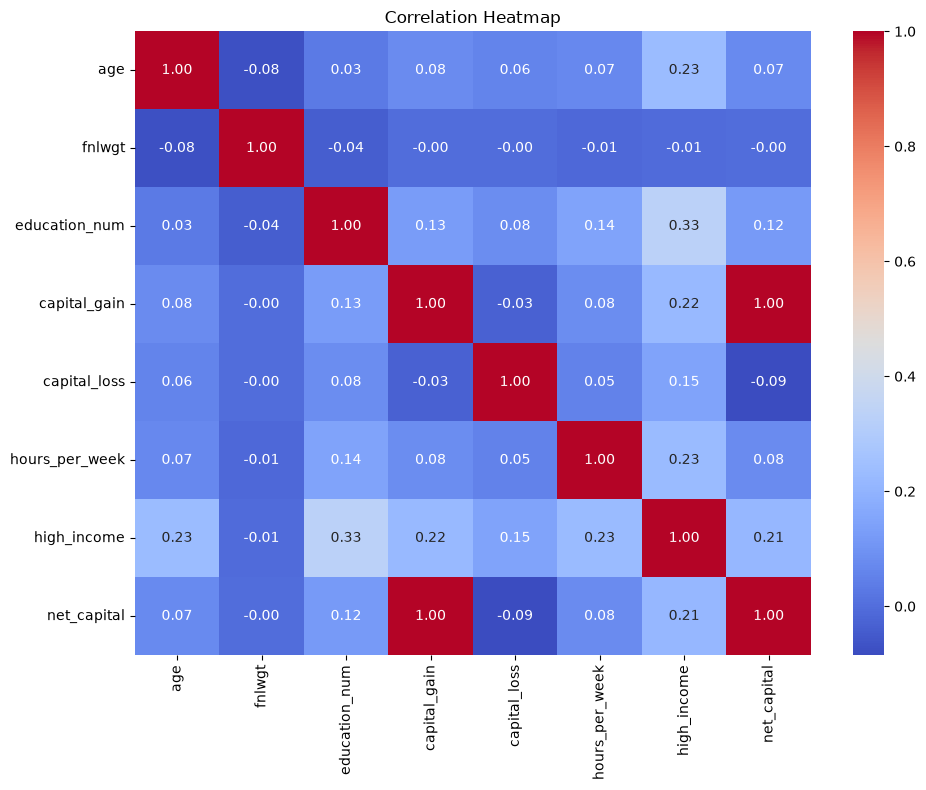

In [38]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "../reports/charts/correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

In [39]:
income_summary = (
    df["income"]
    .value_counts()
    .rename_axis("income")
    .reset_index(name="count")
)

income_summary["percentage"] = (
    income_summary["count"] / len(df) * 100
)

print(income_summary)

  income  count  percentage
0  <=50K  37128   76.061705
1   >50K  11685   23.938295


In [40]:
income_summary.to_csv(
    "../reports/tables/income_summary.csv",
    index=False
)

print("Income summary saved!")

Income summary saved!


In [41]:
education_summary = pd.crosstab(
    df["education"],
    df["income"],
    normalize="index"
) * 100

education_summary = education_summary.reset_index()

print(education_summary)

income     education      <=50K       >50K
0               10th  93.736501   6.263499
1               11th  94.922737   5.077263
2               12th  92.682927   7.317073
3            1st-4th  96.734694   3.265306
4            5th-6th  94.685039   5.314961
5            7th-8th  93.501048   6.498952
6                9th  94.576720   5.423280
7         Assoc-acdm  74.203623  25.796377
8          Assoc-voc  74.660194  25.339806
9          Bachelors  58.690773  41.309227
10         Doctorate  27.441077  72.558923
11           HS-grad  84.141472  15.858528
12           Masters  45.067771  54.932229
13         Preschool  98.780488   1.219512
14       Prof-school  26.019185  73.980815
15      Some-college  81.028613  18.971387


In [42]:
education_summary.to_csv(
    "../reports/tables/education_income_summary.csv",
    index=False
)

print("Education summary saved!")

Education summary saved!


In [43]:
occupation_summary = pd.crosstab(
    df["occupation"],
    df["income"],
    normalize="index"
) * 100

occupation_summary = occupation_summary.reset_index()

print(occupation_summary)

income         occupation      <=50K       >50K
0            Adm-clerical  86.305278  13.694722
1            Armed-Forces  66.666667  33.333333
2            Craft-repair  77.353856  22.646144
3         Exec-managerial  52.202498  47.797502
4         Farming-fishing  88.365837  11.634163
5       Handlers-cleaners  93.336552   6.663448
6       Machine-op-inspct  87.711163  12.288837
7           Other-service  95.852816   4.147184
8         Priv-house-serv  98.750000   1.250000
9          Prof-specialty  54.872710  45.127290
10        Protective-serv  68.667345  31.332655
11                  Sales  73.201308  26.798692
12           Tech-support  70.934256  29.065744
13       Transport-moving  79.575372  20.424628
14                Unknown  90.566038   9.433962


In [44]:
occupation_summary.to_csv(
    "../reports/tables/occupation_income_summary.csv",
    index=False
)

print("Occupation summary saved!")

Occupation summary saved!


In [45]:
age_summary = pd.crosstab(
    df["age_group"],
    df["income"],
    normalize="index"
) * 100

age_summary = age_summary.reset_index()

print(age_summary)

income age_group      <=50K       >50K
0          18-25  98.242147   1.757853
1          26-35  81.286872  18.713128
2          36-45  65.439022  34.560978
3          46-55  60.745297  39.254703
4          56-65  68.593926  31.406074
5            66+  80.188679  19.811321


In [46]:
age_summary.to_csv(
    "../reports/tables/age_income_summary.csv",
    index=False
)

print("Age summary saved!")

Age summary saved!


In [47]:
workclass_summary = pd.crosstab(
    df["workclass"],
    df["income"],
    normalize="index"
) * 100

workclass_summary = workclass_summary.reset_index()

print(workclass_summary)

income         workclass       <=50K       >50K
0            Federal-gov   60.824022  39.175978
1              Local-gov   70.440051  29.559949
2           Never-worked  100.000000   0.000000
3                Private   78.201836  21.798164
4           Self-emp-inc   44.628099  55.371901
5       Self-emp-not-inc   72.105672  27.894328
6              State-gov   73.245835  26.754165
7                Unknown   90.532333   9.467667
8            Without-pay   90.476190   9.523810


In [48]:
workclass_summary.to_csv(
    "../reports/tables/workclass_income_summary.csv",
    index=False
)

print("Workclass summary saved!")

Workclass summary saved!


In [49]:
sex_summary = pd.crosstab(
    df["sex"],
    df["income"],
    normalize="index"
) * 100

sex_summary = sex_summary.reset_index()

print(sex_summary)

income     sex      <=50K       >50K
0       Female  89.068100  10.931900
1         Male  69.611719  30.388281


In [50]:
sex_summary.to_csv(
    "../reports/tables/sex_income_summary.csv",
    index=False
)

print("Sex summary saved!")

Sex summary saved!


In [51]:
hours_summary = pd.crosstab(
    df["hours_group"],
    df["income"],
    normalize="index"
) * 100

hours_summary = hours_summary.reset_index()

print(hours_summary)

income hours_group      <=50K       >50K
0             0-20  93.232914   6.767086
1            21-40  81.201279  18.798721
2            41-60  59.419146  40.580854
3              61+  64.260143  35.739857


In [52]:
hours_summary.to_csv(
    "../reports/tables/hours_income_summary.csv",
    index=False
)

print("Hours summary saved!")

Hours summary saved!


In [53]:
pip install python-docx

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   --------------- ------------------------ 1.6/4.0 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 10.8 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   -------------------- ------------------- 1/2 [python-docx]
   ---------------------------------------- 2/2 [python-docx]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
from docx import Document
from docx.shared import Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
import os

# Create Word document
doc = Document()

# Title
title = doc.add_heading("Adult Income Data Cleaning and EDA Report", 0)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

# Project Summary
doc.add_heading("1. Project Summary", level=1)
doc.add_paragraph(
    "This project analyzes the UCI Adult Income dataset to understand "
    "which demographic, education, and work-related characteristics "
    "are associated with annual income above USD 50K."
)

# Problem Statement
doc.add_heading("2. Problem Statement", level=1)
doc.add_paragraph(
    "Which demographic, education, and work characteristics are associated "
    "with an annual income above USD 50K in this census dataset?"
)

# Dataset
doc.add_heading("3. Dataset Overview", level=1)
doc.add_paragraph(
    "The dataset is the Adult Income dataset from the UCI Machine Learning "
    "Repository. The training and testing files were combined for analysis."
)

doc.add_paragraph("Total records: 48,842")
doc.add_paragraph("Original features: 14")
doc.add_paragraph("Target variable: income")

# Data Cleaning
doc.add_heading("4. Data Cleaning", level=1)

cleaning_steps = [
    "Combined adult.data and adult.test datasets.",
    "Added source_split to identify train and test records.",
    "Replaced '?' missing-value markers with NaN.",
    "Replaced missing workclass, occupation, and native_country values with 'Unknown'.",
    "Removed the trailing period from income labels in the test dataset.",
    "Created the high_income numeric variable.",
    "Created age_group and hours_group variables.",
    "Created net_capital using capital_gain minus capital_loss.",
    "Counted duplicate records without removing them."
]

for step in cleaning_steps:
    doc.add_paragraph(step, style="List Bullet")

# EDA
doc.add_heading("5. Exploratory Data Analysis", level=1)
doc.add_paragraph(
    "The analysis examined income distribution and relationships between "
    "income and education, occupation, age, workclass, sex, working hours, "
    "and capital-related variables."
)

# Charts
charts = [
    ("Income Distribution", "income_distribution.png"),
    ("Income by Education", "education_income.png"),
    ("Income by Occupation", "occupation_income.png"),
    ("Income by Age Group", "age_income.png"),
    ("Income by Workclass", "workclass_income.png"),
    ("Income by Sex", "sex_income.png"),
    ("Weekly Working Hours by Income", "hours_income_boxplot.png"),
    ("Income by Working-Hour Group", "hours_income.png"),
    ("Correlation Heatmap", "correlation_heatmap.png")
]

for heading, filename in charts:
    path = f"../reports/charts/{filename}"

    if os.path.exists(path):
        doc.add_heading(heading, level=2)
        doc.add_picture(path, width=Inches(6))
        last_paragraph = doc.paragraphs[-1]
        last_paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER

# Limitations
doc.add_heading("6. Limitations", level=1)
doc.add_paragraph(
    "This analysis describes associations in the dataset and does not "
    "establish causal relationships. The Adult dataset is historical and "
    "contains demographic attributes. The visualizations are descriptive "
    "and are not weighted to represent a modern population."
)

# Conclusion
doc.add_heading("7. Conclusion", level=1)
doc.add_paragraph(
    "The exploratory analysis provides an overview of how education, "
    "occupation, age, workclass, sex, working hours, and capital-related "
    "variables are associated with income levels in the Adult dataset. "
    "The cleaned dataset and EDA results can be used as the foundation "
    "for the machine-learning stage of the project."
)

# Save report
output_path = "../reports/EDA_Report.docx"
doc.save(output_path)

print("EDA Word report created successfully!")
print("Saved at:", output_path)

EDA Word report created successfully!
Saved at: ../reports/EDA_Report.docx


In [58]:
import sys

print(sys.executable)

c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\python.exe


In [61]:
%pip install reportlab

  Using cached reportlab-5.0.1-py3-none-any.whl.metadata (1.6 kB)
Using cached reportlab-5.0.1-py3-none-any.whl (2.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
from reportlab.lib.pagesizes import A4

print("ReportLab is working!")

ReportLab is working!


In [64]:
import sys
!{sys.executable} -m pip install reportlab


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
